# Problem Statement
***Which customers and products drive repeat revenue, and how can the business improve retention?***

#### Importing necessary libraries and reading the data from an excel file

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
!pip install python-calamine

In [2]:
# Reading the excel file
df = pd.read_excel(r"D:\online+retail\Online Retail.xlsx", engine="calamine")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Dataset Description
This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.   

#### Column description
 - **InvoiceNo:** 6-digit transaction ID. Codes starting with "C" mean a cancellation.
 - **StockCode:** 5-digit product ID.
 - **Description:** Product name.
 - **Quantity:** Number of items bought per transaction.
 - **InvoiceDate:** Date and time of the transaction.
 - **UnitPrice:** Price per unit in British Pounds (£).
 - **CustomerID:** 5-digit unique customer ID.
 - **Country:** Country where the customer lives.

# Data cleaning

In [3]:
# Number of rows and columns in the dataset
print("Rows: ", df.shape[0])
print("Columns: ", df.shape[1])

Rows:  541909
Columns:  8


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
# Number of Null values in each column
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
# Dropping all the rows with NaN in CustomerID column
df.dropna(subset=['CustomerID'],inplace=True)
print(f'shape: {df.shape}\n')

shape: (406829, 8)



In [7]:
# Checking if null values still exist
print(df.isna().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [9]:
# Checking duplicate rows
print('Number of duplicate records', df.duplicated().sum())

Number of duplicate records 5225


In [12]:
df[df.duplicated(keep=False)].sort_values(by=['InvoiceNo','StockCode'])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...
440149,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,2011-11-04 13:25:00,2.95,15110.0,United Kingdom
461407,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
461408,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
529980,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom


In [13]:
# deleting the duplicate rows
df = df.drop_duplicates(keep='first')

In [14]:
print('Number of duplicate records', df.duplicated().sum())

Number of duplicate records 0


## **Exploring Each Column**

### InvoiceNo

In [15]:
print("The datatype of InvoiceNo column: ", df['InvoiceNo'].dtype)

The datatype of InvoiceNo column:  object


In [16]:
# Checking if the InvoiceNo column has mixed data types
df['InvoiceNo'].apply(type).value_counts()

InvoiceNo
<class 'int'>    392732
<class 'str'>      8872
Name: count, dtype: int64

In [17]:
# Changing the dtype to 'string'
df['InvoiceNo'] = df['InvoiceNo'].astype('string')

In [18]:
# Now again checking if it still has mixed data types
df['InvoiceNo'].apply(type).nunique()

1

In [19]:
# Removing all the cancelled orders
# InvoiceNo of Cancelled orders starts with "C"

df = df[~df['InvoiceNo'].str.startswith('C')]

In [20]:
df.shape

(392732, 8)

In [21]:
# Checking number of unique values in Invoice column
df['InvoiceNo'].nunique()

18536

### **StockCode**

In [22]:
# Checking Dtype
print("The datatype of StockCode column: ", df['StockCode'].dtype)

The datatype of StockCode column:  object


In [23]:
# Checking if the StockCode column has mixed data types
df['StockCode'].apply(type).value_counts()

StockCode
<class 'int'>    358309
<class 'str'>     34423
Name: count, dtype: int64

In [24]:
# Changing the dtype to 'string'
df['StockCode'] = df['StockCode'].astype('string').str.upper()

In [25]:
# Now again checking if it still has mixed data types
df['InvoiceNo'].apply(type).nunique()

1

In [26]:
# Checking number of unique values 
df['StockCode'].nunique()

3665

### **Description**

In [27]:
# Dtype
print("The datatype of Description column: ", df['Description'].dtype)

The datatype of Description column:  object


In [28]:
# Checking No. of Nan values 
df['Description'].isna().sum()

0

In [29]:
# Checking if the Description column has mixed data types
df['Description'].apply(type).value_counts()

Description
<class 'str'>    392732
Name: count, dtype: int64

In [30]:
# Checking number of unique values 
df['Description'].nunique()

3877

In [31]:
# No. of unique values for description is more than that for stockcode.
# Chances are there can be multiple variations of the same product name.

# Let's verify this

# Count of Product names(Description) for each stockcode
product = df.groupby('StockCode')['Description'].nunique()

# stockcodes with multiple product names
productid = product[product>1].index.to_list()

multiple_product_name = df[df['StockCode'].isin(productid)][['StockCode','Description']].sort_values(by='StockCode')
multiple_product_name


,StockCode,Description
108353,16156L,"WRAP, CAROUSEL"
277189,16156L,WRAP CAROUSEL
185086,16156L,WRAP CAROUSEL
331977,16156L,WRAP CAROUSEL
193106,16156L,WRAP CAROUSEL
...,...,...
180447,90014B,GOLD M PEARL ORBIT NECKLACE
28450,90014B,GOLD M PEARL ORBIT NECKLACE
305558,90014C,SILVER/BLACK ORBIT NECKLACE
142063,90014C,SILVER/BLACK ORBIT NECKLACE


In [32]:
# For each stockcode, let's find the first value of description then we will join this dataframe with original on stockcode

In [33]:
unique_names = df.groupby('StockCode')['Description'].first().str.capitalize().str.strip().reset_index().rename(columns={'Description':'ProductName'})

# Joining with original column
df = df.merge(unique_names, how='inner', on='StockCode').drop(columns='Description')
df

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ProductName
0,536365,85123A,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,White hanging heart t-light holder
1,536365,71053,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,White metal lantern
2,536365,84406B,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Cream cupid hearts coat hanger
3,536365,84029G,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Knitted union flag hot water bottle
4,536365,84029E,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Red woolly hottie white heart.
...,...,...,...,...,...,...,...,...
392727,581587,22613,12,2011-12-09 12:50:00,0.85,12680.0,France,Pack of 20 spaceboy napkins
392728,581587,22899,6,2011-12-09 12:50:00,2.10,12680.0,France,Children's apron dolly girl
392729,581587,23254,4,2011-12-09 12:50:00,4.15,12680.0,France,Childrens cutlery dolly girl
392730,581587,23255,4,2011-12-09 12:50:00,4.15,12680.0,France,Childrens cutlery circus parade


In [34]:
# Moving ProductName besides StockCode
col = df.pop('ProductName')

# inserting product name at index 2
df.insert(2,'ProductName',col)

In [35]:
df.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,White hanging heart t-light holder,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,White metal lantern,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,Cream cupid hearts coat hanger,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,Knitted union flag hot water bottle,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,Red woolly hottie white heart.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [36]:
# Checking unique count of productname
df['ProductName'].nunique()

3639

In [37]:
# Distinct count of Stockcode
df['StockCode'].nunique()

3665

In [38]:
# Still there is a difference b/w the numbers of the two
# Investigating it further

In [39]:
# Grouping by Product Name to see if there are multiple stockcodes with same name
product_name = unique_names.groupby('ProductName')['StockCode'].nunique()

# Product name list with more than 1 distinct stockcodes
product_list = product_name[product_name>1].index

unique_names[unique_names['ProductName'].isin(product_list)].sort_values(by='ProductName')

,StockCode,ProductName
2777,82580,Bathroom metal sign
394,21171,Bathroom metal sign
7,10133,Colouring pencils brown tube
8,10135,Colouring pencils brown tube
2664,72131,Columbian candle rectangle
2666,72133,Columbian candle rectangle
2663,72130,Columbian candle round
2662,72128,Columbian candle round
2661,72127,Columbian candle round
3152,85023B,Eau de nile jewelled photoframe


In [40]:
# It is fairly possible to have same product description for different products. 
# Might be because of different brands but similar product or same product but different color or size

### **Quantity**

In [41]:
# Dtype
df['Quantity'].dtype

dtype('int64')

In [66]:
df['Quantity'].value_counts()

Quantity
1        69605
12       59828
2        57425
6        37480
4        32093
         ...  
4300         1
608          1
738          1
552          1
80995        1
Name: count, Length: 302, dtype: int64

In [42]:
# Descriptive statistics
df['Quantity'].describe()

count    392732.000000
mean         13.153718
std         181.588420
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [43]:
# Since the max vlaue in Quantity Column is 80995 we can convert its data type from int64 to int32 to save some memory
df['Quantity'] =  df['Quantity'].astype(np.int32) 

(array([3.92729e+05, 1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 2.00000e+00]),
 array([1.00000e+00, 8.10040e+03, 1.61998e+04, 2.42992e+04, 3.23986e+04,
        4.04980e+04, 4.85974e+04, 5.66968e+04, 6.47962e+04, 7.28956e+04,
        8.09950e+04]),
 <BarContainer object of 10 artists>)

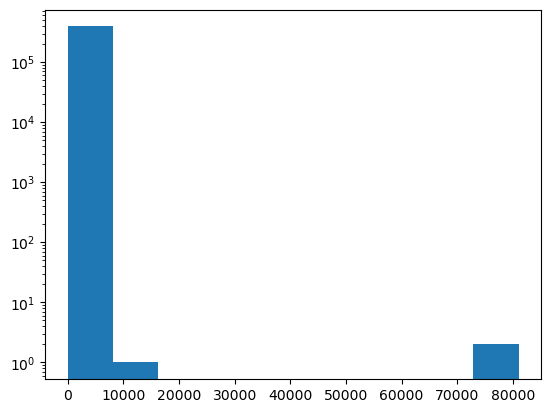

In [44]:
# Plotting a histogram 
plt.hist(df['Quantity'],log=True)

<Axes: ylabel='Quantity'>

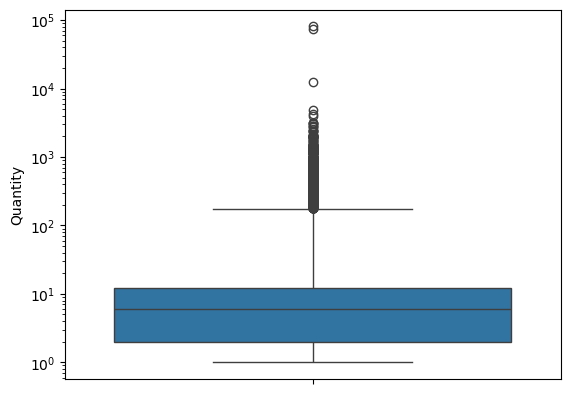

In [45]:
# Boxplot
sns.boxplot(df['Quantity'],log_scale=True)

### InvoiceDate

In [46]:
# Dtype
df['InvoiceDate'].dtype

dtype('<M8[ns]')

In [47]:
# No. of Null values
df['InvoiceDate'].isna().sum()

0

In [48]:
# Checking the first and last date
print('First date:', df['InvoiceDate'].min().date())
print('Last date:', df['InvoiceDate'].max().date())

First date: 2010-12-01
Last date: 2011-12-09


### UnitPrice

In [42]:
# Dtype
df['UnitPrice'].dtype

dtype('float64')

In [49]:
# descriptive statistics
df['UnitPrice'].describe()

count    392732.000000
mean          3.125596
std          22.240725
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max        8142.750000
Name: UnitPrice, dtype: float64

(array([3.92706e+05, 1.30000e+01, 7.00000e+00, 2.00000e+00, 1.00000e+00,
        2.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00]),
 array([   0.   ,  814.275, 1628.55 , 2442.825, 3257.1  , 4071.375,
        4885.65 , 5699.925, 6514.2  , 7328.475, 8142.75 ]),
 <BarContainer object of 10 artists>)

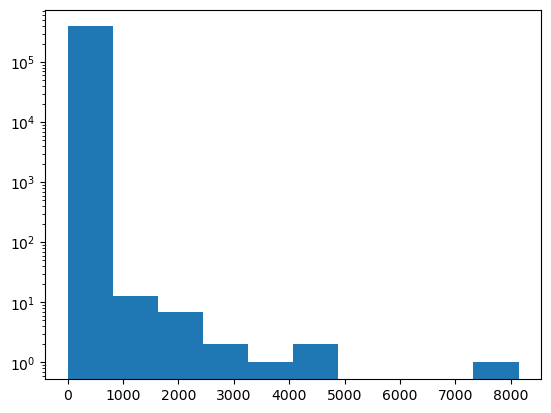

In [50]:
# Plotting the histogram
plt.hist(df['UnitPrice'],log=True)

<Axes: ylabel='UnitPrice'>

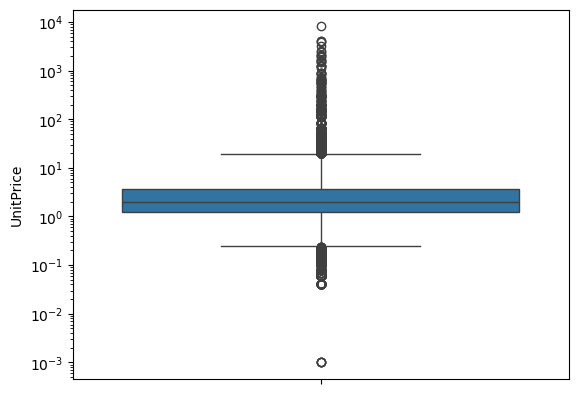

In [51]:
# Box plot
sns.boxplot(df['UnitPrice'], log_scale=True)

### CustomerID

In [52]:
# Dtype
df['CustomerID'].dtype

dtype('float64')

In [53]:
# No. of Null values
df['CustomerID'].isna().sum()

0

In [54]:
# First convert the dtype to int then to string to remove decimal and trailing zeros
df['CustomerID'] = df['CustomerID'].astype(np.int64).astype('string')

In [55]:
df['CustomerID'].head()

0    17850
1    17850
2    17850
3    17850
4    17850
Name: CustomerID, dtype: string

In [56]:
# Number of Distinct customers
df['CustomerID'].nunique()

4339

### Country

In [57]:
# Dtype
df['Country'].dtype

dtype('O')

In [58]:
# Checking if it has mixed types
df['Country'].apply(type).nunique()

1

In [59]:
# Converting to string
df['Country'] = df['Country'].astype('string')

In [60]:
# Unique values in the column
df['Country'].unique()

<StringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Finland',
              'Austria',               'Greece',            'Singapore',
              'Lebanon', 'United Arab Emirates',               'Israel',
         'Saudi Arabia',       'Czech Republic',               'Canada',
          'Unspecified',               'Brazil',                  'USA',
   'European Community',              'Bahrain',                'Malta',
                  'RSA']
Length: 37, dtype: string

In [61]:
# Adding a sales Column 
df['Sales'] = df['Quantity']*df['UnitPrice']

### Metrics

In [63]:
# Total Revenue generated
print(f"\nTotal revenue generated: {df['Sales'].sum().round()}")

# Total customers
print(f"\nTotal customers: {df['CustomerID'].nunique()}")

# Total Products
print(f"\nTotal products: {df['StockCode'].nunique()}")

# Total Orders
print(f"\nTotal orders: {df['InvoiceNo'].nunique()}")


Total revenue generated: 8887209.0

Total customers: 4339

Total products: 3665

Total orders: 18536


## Findings
- *There can be multiple products in a single order.*
- *The Retail store has 3665 listed products.*
- *75% values in Quantity column are less than 12*
- *75% products has a unit price less than 3.75 Euros*
- *The store has 4339 customers*
- *The store has customers in 37 countries*
- *The store has generated a total revenue of 8.9M Euros*
- *The store has processed around 18500 orders b/w dec 2010 and dec 2011*

In [65]:
# Saving the cleaned dataframe to an excel file 

df.to_excel('retail_clean_dataset.xlsx', index=False)

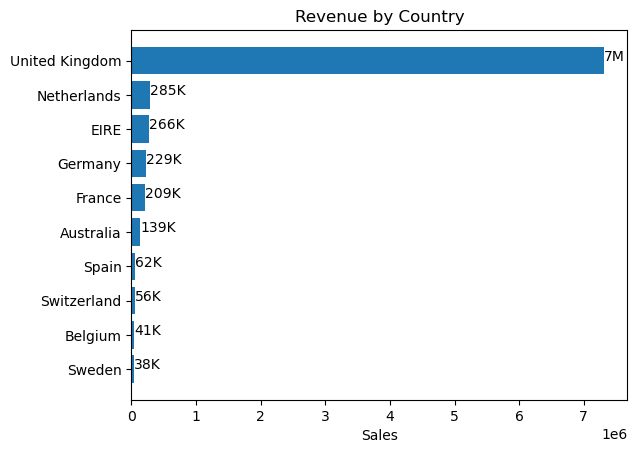

In [58]:
countrywise_sales = df.groupby('Country')['Sales'].sum().sort_values(ascending=False).head(10).sort_values()
plt.barh(countrywise_sales.index, countrywise_sales.values)
plt.title('Revenue by Country')
plt.xlabel('Sales')
for x,y in enumerate(countrywise_sales.values):
    if y/1000000<1:
        sales = f"{round(y/1000)}K"
    else:
        sales = f"{round(y/1000000)}M"
    plt.annotate(sales, (y+200,x))

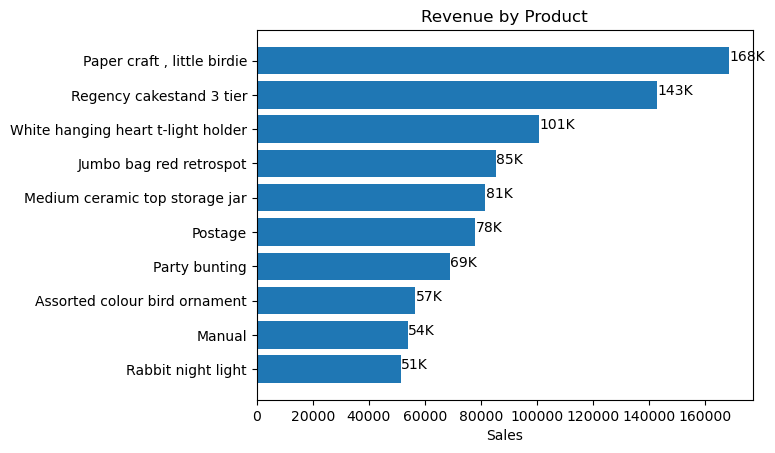

In [59]:
productwise_sales = df.groupby('ProductName')['Sales'].sum().sort_values(ascending=False).head(10).sort_values()
plt.barh(productwise_sales.index, productwise_sales.values)
plt.title('Revenue by Product')
plt.xlabel('Sales')
for x,y in enumerate(productwise_sales.values):
    if y/1000000<1:
        sales = f"{round(y/1000)}K"
    else:
        sales = f"{round(y/1000000)}M"
    plt.annotate(sales, (y+200,x))

In [60]:
 df['MonthYear'] = df['InvoiceDate'].dt.strftime("%b-%Y")

In [61]:
# Converting MonthYear to categorical type
month_order = ['Dec-2010', 'Jan-2011', 'Feb-2011', 'Mar-2011', 'Apr-2011', 'May-2011', 'Jun-2011', 'Jul-2011',
              'Aug-2011', 'Sep-2011', 'Oct-2011', 'Nov-2011', 'Dec-2011']

df['MonthYear'] = pd.Categorical(df['MonthYear'], categories=month_order, ordered=True)

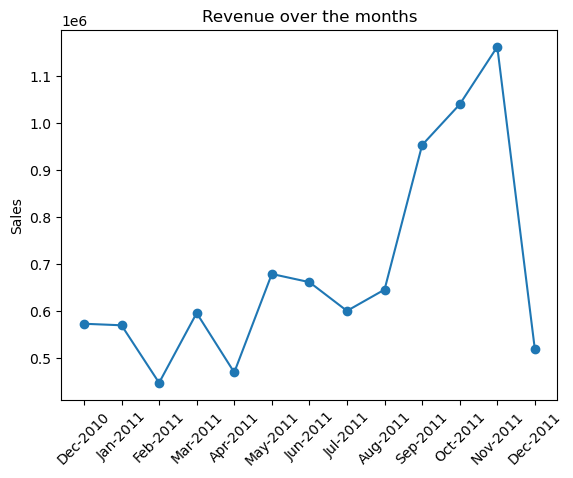

In [62]:
monthly_sales = df.groupby('MonthYear')['Sales'].sum()
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title('Revenue over the months')
plt.ylabel('Sales')
xticks = plt.xticks(rotation=45)

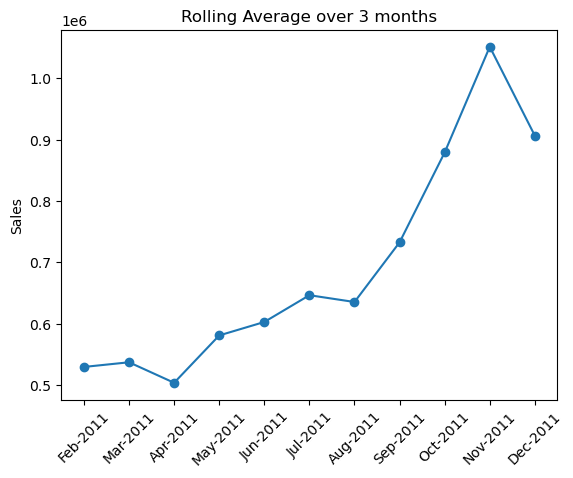

In [63]:
rolling_sales = monthly_sales.rolling(window=3).mean()
plt.plot(rolling_sales.index, rolling_sales.values, marker='o')
plt.title('Rolling Average over 3 months')
plt.ylabel('Sales')
x = plt.xticks(rotation=45)

In [64]:
# Setting an analysis date (1 day after the most recent date in the data)
analysis_date = df['InvoiceDate'].max()+pd.DateOffset(days=1)
analysis_date

Timestamp('2011-12-10 12:50:00')

In [65]:
# Calcualting raw R,F,M values
rfm= df.groupby('CustomerID').agg(Recency= ('InvoiceDate',lambda x:(analysis_date - x.max()).days),
                                         Frequency = ('InvoiceNo', lambda x:x.nunique()),
                                         Monetary = ('Sales', sum)).reset_index()
rfm

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
...,...,...,...,...
4334,18280,278,1,180.60
4335,18281,181,1,80.82
4336,18282,8,2,178.05
4337,18283,4,16,2094.88


In [66]:
# Assigning RFM scores using quintiles(q=5)
# For Recency lower values means higher score
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5,4,3,2,1])

# For Frequency higher value is better
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1,2,3,4,5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1,2,3,4,5])
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,1,77183.60,1,1,5
1,12347,2,7,4310.00,5,5,5
2,12348,75,4,1797.24,2,4,4
3,12349,19,1,1757.55,4,1,4
4,12350,310,1,334.40,1,1,2


In [67]:
# Customer segmentation logic
def assign_segment(row):
    r = int(row['R_Score'])
    f = int(row['F_Score'])
    m = int(row['M_Score'])

    # Champions: Bought most recently, buy most often and spend the most
    if r>=4 and f>=4 and m>=4:
        return 'Champions'
    # loyal Customers: Buy on a regula basis
    elif r>=3 and f>=3:
        return 'Loyal Customers'
    # New Customers: Bought very recently but only once
    elif r>=4 and f>=1:
        return 'New Customers'
    # At risk: high frequency but recency is dropping
    elif r<=2 and f>=3 and m>=4:
        return 'At risk'
    # Lost: Lowest recency and frequency
    else:
        return 'Lost'

rfm['Customer_Segment'] = rfm.apply(assign_segment, axis=1 )
rfm.head()


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Customer_Segment
0,12346,326,1,77183.60,1,1,5,Lost
1,12347,2,7,4310.00,5,5,5,Champions
2,12348,75,4,1797.24,2,4,4,At risk
3,12349,19,1,1757.55,4,1,4,New Customers
4,12350,310,1,334.40,1,1,2,Lost


In [68]:
# # Customer segmentation
# def assign_segment(row):
#     r = int(row['R_Score'])
#     f = int(row['F_Score'])
#     m = int(row['M_Score'])

#     # Champions: Bought most recently, buy most often and spend the most
#     if r>=4 and f>=4 and m>=4:
#         return 'Champions'
#     # loyal Customers: Buy on a regula basis
#     elif r>=3 and f>=3:
#         return 'Loyal Customers'
#     # Potential Loyalists: Recent customers showing some repeat behaviour
#     elif r>=4 and f>=2:
#         return 'Potential loyalists'
#     # New Customers: Bought very recently but only once
#     elif r>=4 and f==1:
#         return 'New Customers'
#     # Can't lose them: High Frequency and high monetary, but haven't returned in a long time
#     elif r==1 and f>=4 and m>=4:
#         return "Can't lose them"
#     # At risk: high frequency but recency is dropping
#     elif r<=2 and f>=3:
#         return 'At risk'
#     # Needing Attention: Below Average recency and frequency
#     elif r==2 and f<=2:
#         return 'Needing Attention'
#     # Lost: Lowest recency and frequency
#     else:
#         return 'Lost'

# rfm['Customer_Segment'] = rfm.apply(assign_segment, axis=1 )
# rfm.head()


In [69]:
# Generating segment summary
segment_summary = rfm.groupby('Customer_Segment').agg(Avg_Recency=('Recency','mean'), 
                                                      Avg_Frequency = ('Frequency', 'mean'), 
                                                      Avg_Monetary = ('Monetary', 'mean'), 
                                                      Total_Revenue = ('Monetary', 'sum')).reset_index()
segment_summary['% of Total Revenue'] = round(segment_summary['Total_Revenue'].div(rfm['Monetary'].sum())*100,1)
segment_summary.sort_values(by=['% of Total Revenue','Avg_Monetary'], ascending = False)

,Customer_Segment,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,% of Total Revenue
1,Champions,12.861746,11.082121,6038.816081,5809341.070,65.2
3,Loyal Customers,34.091182,3.714429,1477.081714,1474127.551,16.5
2,Lost,174.808652,1.454798,485.929491,876130.873,9.8
0,At risk,132.578125,4.484375,2365.788437,605641.840,6.8
4,New Customers,18.503125,1.240625,456.770531,146166.570,1.6


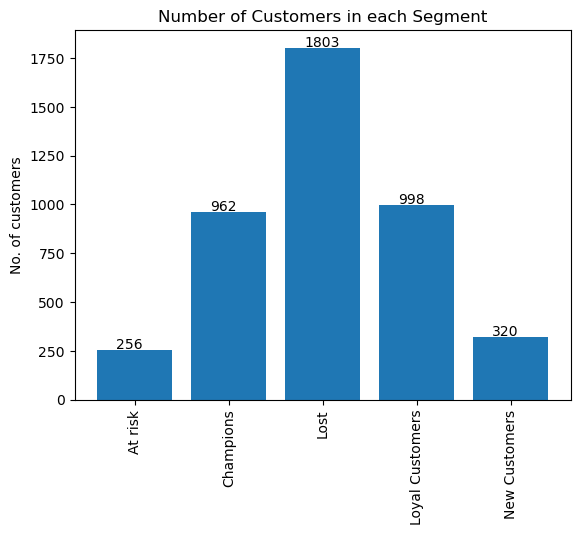

In [70]:
# Customer count in each segment
segment_count = rfm.groupby('Customer_Segment')['CustomerID'].nunique()
plt.bar(segment_count.index, segment_count.values)
plt.title('Number of Customers in each Segment')
plt.ylabel('No. of customers')
plt.xticks(rotation=90)
for x,y in enumerate(segment_count.values):
    plt.annotate(y,(x-0.2,y+5))

In [132]:
segment_count.div(segment_count.sum())*100

Customer_Segment
At risk             5.899977
Champions          22.171007
Lost               41.553353
Loyal Customers    23.000691
New Customers       7.374971
Name: CustomerID, dtype: float64

<Axes: xlabel='Recency', ylabel='Frequency'>

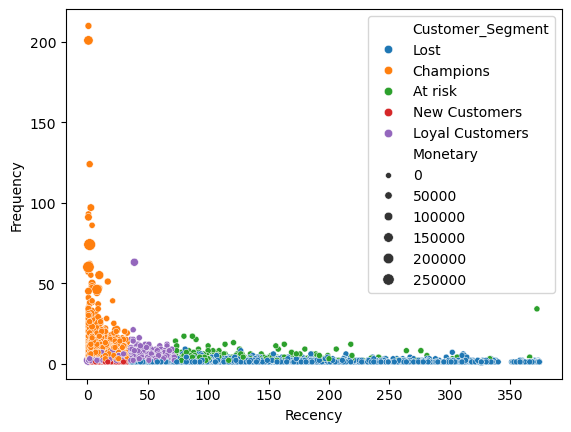

In [71]:
# scatterplot of recency and frequency
sns.scatterplot(data=rfm, y='Frequency', x='Recency', size='Monetary', hue='Customer_Segment')

In [72]:
# treemap
import plotly.express as px
fig = px.treemap(rfm, path=['Customer_Segment'], values='Monetary')
fig.show()

Chorots are based on the month of first purchase made by the customers

In [73]:
# First purchase of each customer
cohort = df.groupby('CustomerID')['InvoiceDate'].min().dt.strftime('%b %Y').reset_index().rename(columns={'InvoiceDate': 'Cohort'})
cohort.head()

,CustomerID,Cohort
0,12346,Jan 2011
1,12347,Dec 2010
2,12348,Dec 2010
3,12349,Nov 2011
4,12350,Feb 2011


In [74]:
# Merging with the original column
df = df.merge(cohort, how='inner', on='CustomerID')
df.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,MonthYear,Cohort
0,536365,85123A,White hanging heart t-light holder,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,Dec-2010,Dec 2010
1,536365,71053,White metal lantern,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010
2,536365,84406B,Cream cupid hearts coat hanger,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,Dec-2010,Dec 2010
3,536365,84029G,Knitted union flag hot water bottle,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010
4,536365,84029E,Red woolly hottie white heart.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010


In [75]:
# Calculating cohort index

Now we calculate how many months have passed between a specific purchase and the customer's initial cohort month. Month 0 is their first purchase, Month 1 is the following month, etc.

In [76]:
order_month = df['InvoiceDate'].dt.to_period('M').astype('int64')
cohort_month = pd.DatetimeIndex(df['Cohort']).to_period('M').astype('int64')
diff = order_month - cohort_month
df['CohortIndex'] = diff.apply(lambda x: f"Month {x}")
df.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,MonthYear,Cohort,CohortIndex
0,536365,85123A,White hanging heart t-light holder,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,Dec-2010,Dec 2010,Month 0
1,536365,71053,White metal lantern,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0
2,536365,84406B,Cream cupid hearts coat hanger,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,Dec-2010,Dec 2010,Month 0
3,536365,84029G,Knitted union flag hot water bottle,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0
4,536365,84029E,Red woolly hottie white heart.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0


In [77]:
# Conveting Cohort Column to categorical to have months in correct calender order
month_order = ['Dec 2010', 'Jan 2011', 'Feb 2011', 'Mar 2011', 'Apr 2011', 'May 2011', 'Jun 2011', 
               'Jul 2011', 'Aug 2011', 'Sep 2011', 'Oct 2011', 'Nov 2011', 'Dec 2011']
df['Cohort'] = pd.Categorical(df['Cohort'], categories=month_order, ordered=True)

In [78]:
# Converting CohortIndex to categorical
order = [f'Month {x}' for x in range(13)]
df['CohortIndex'] = pd.Categorical(df['CohortIndex'], categories=order, ordered=True)

In [79]:
# Converting to Pivot table
cohort_table = df.pivot_table(index='Cohort', columns='CohortIndex', values='CustomerID', aggfunc='nunique')
cohort_table[cohort_table==0]=np.nan
cohort_table

CohortIndex,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,Month 11,Month 12
Cohort,,,,,,,,,,,,,
Dec 2010,885,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
Jan 2011,417,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
Feb 2011,380,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
Mar 2011,452,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
Apr 2011,300,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
May 2011,284,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
Jun 2011,242,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
Jul 2011,188,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Aug 2011,169,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [80]:
# Converting absolute values to percentage
cohort_size = cohort_table.iloc[:,0]
retention = cohort_table.div(cohort_size, axis=0)
retention

CohortIndex,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,Month 11,Month 12
Cohort,,,,,,,,,,,,,
Dec 2010,1.0,0.366102,0.323164,0.384181,0.362712,0.397740,0.362712,0.349153,0.353672,0.395480,0.374011,0.502825,0.265537
Jan 2011,1.0,0.220624,0.266187,0.230216,0.321343,0.287770,0.247002,0.242206,0.299760,0.326139,0.364508,0.117506,NaN
Feb 2011,1.0,0.186842,0.186842,0.284211,0.271053,0.247368,0.252632,0.278947,0.247368,0.305263,0.068421,NaN,NaN
Mar 2011,1.0,0.150442,0.252212,0.199115,0.223451,0.168142,0.267699,0.230088,0.278761,0.086283,NaN,NaN,NaN
Apr 2011,1.0,0.213333,0.203333,0.210000,0.196667,0.226667,0.216667,0.260000,0.073333,NaN,NaN,NaN,NaN
May 2011,1.0,0.190141,0.172535,0.172535,0.207746,0.232394,0.264085,0.095070,NaN,NaN,NaN,NaN,NaN
Jun 2011,1.0,0.173554,0.157025,0.264463,0.231405,0.334711,0.095041,NaN,NaN,NaN,NaN,NaN,NaN
Jul 2011,1.0,0.180851,0.207447,0.223404,0.271277,0.111702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Aug 2011,1.0,0.207101,0.248521,0.242604,0.124260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Text(0.5, 80.7222222222222, 'Months Since First Purchase')

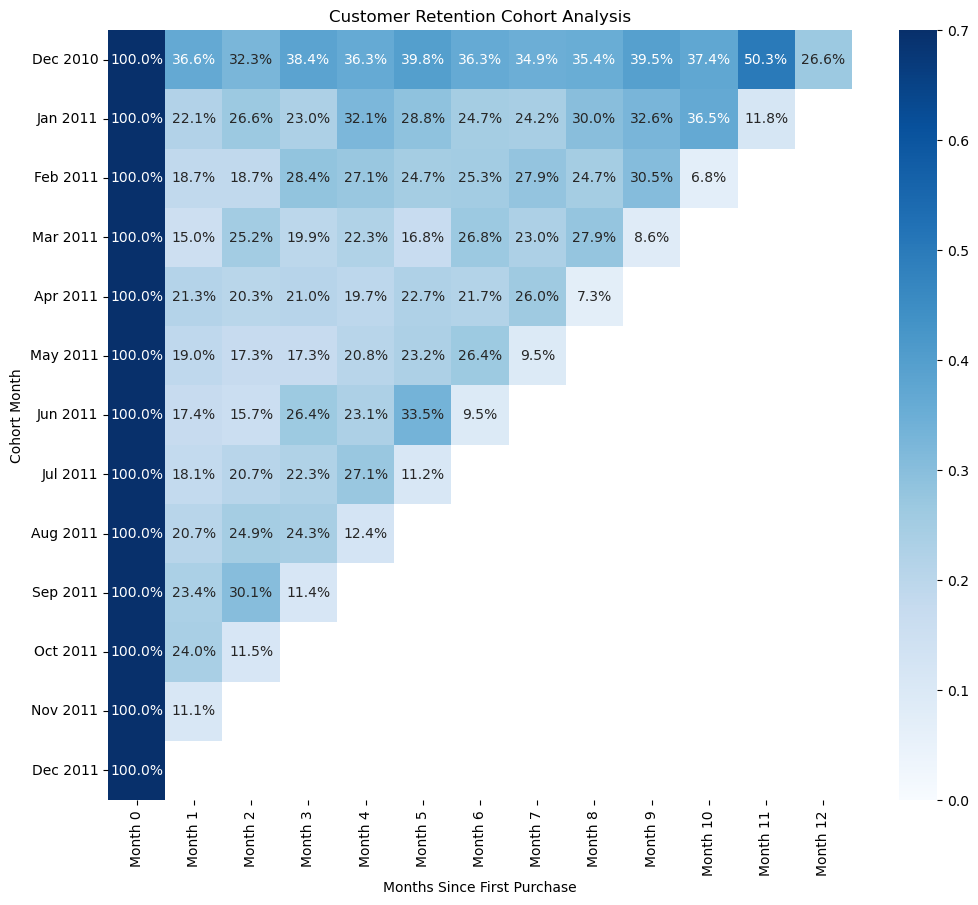

In [81]:
# Plotting the heatmap
plt.figure(figsize=(12,10))
plt.title('Customer Retention Cohort Analysis')
sns.heatmap(retention, 
            annot=True,
            fmt=".1%",
            vmin=0,
            vmax=0.7,
            cmap='Blues')
plt.ylabel('Cohort Month')
plt.xlabel('Months Since First Purchase')

Text(0.5, 80.7222222222222, 'Months Since First Purchase')

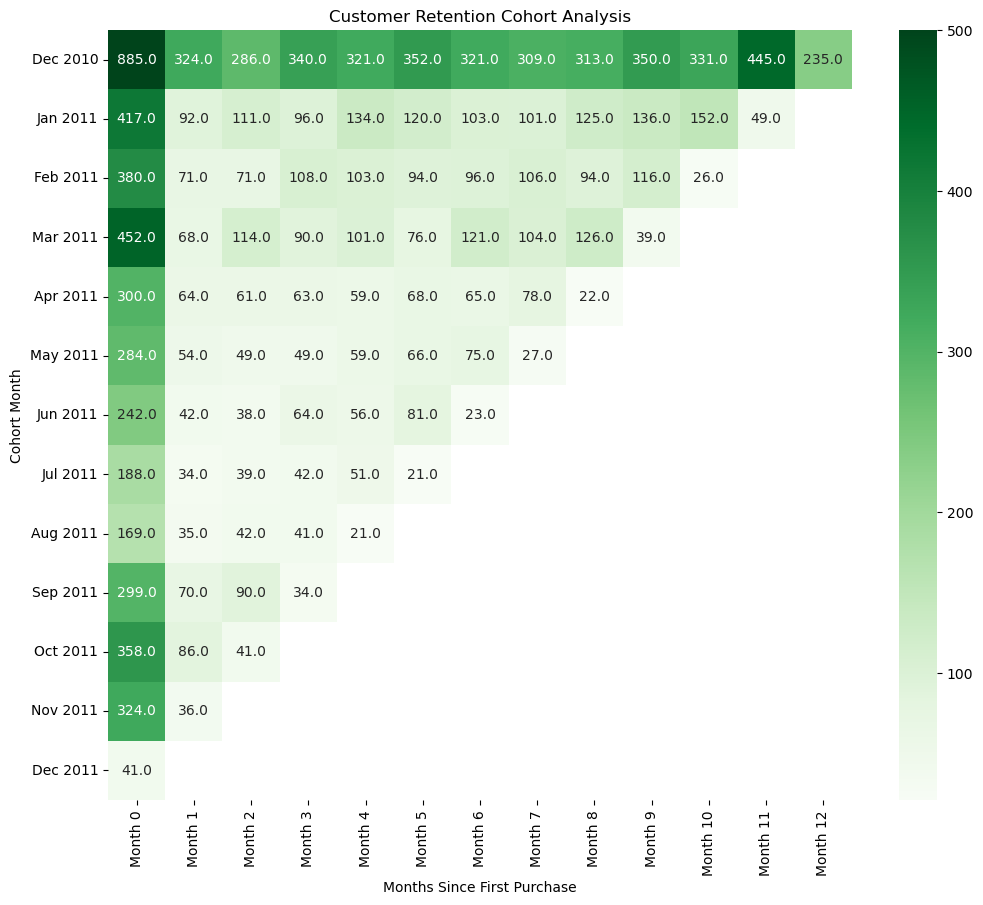

In [82]:
# Plotting the heatmap
plt.figure(figsize=(12,10))
plt.title('Customer Retention Cohort Analysis')
sns.heatmap(cohort_table, 
            annot=True,
            fmt="0",
            vmax=500,
            cmap='Greens')
plt.ylabel('Cohort Month')
plt.xlabel('Months Since First Purchase')

### Combining rfm and cohort analysis to see the early retention curves of our customer segments

In [83]:
# Joining the rfm data with original data
df = df.merge(rfm[['CustomerID','Customer_Segment']], how='inner', on='CustomerID')
df.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,MonthYear,Cohort,CohortIndex,Customer_Segment
0,536365,85123A,White hanging heart t-light holder,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,Dec-2010,Dec 2010,Month 0,At risk
1,536365,71053,White metal lantern,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0,At risk
2,536365,84406B,Cream cupid hearts coat hanger,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,Dec-2010,Dec 2010,Month 0,At risk
3,536365,84029G,Knitted union flag hot water bottle,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0,At risk
4,536365,84029E,Red woolly hottie white heart.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,Dec-2010,Dec 2010,Month 0,At risk


In [84]:
# Grouping on Customer segment and CohortIndex to find customer count per segment per month
segment_cohort = df.groupby(['Customer_Segment','CohortIndex'])['CustomerID'].nunique().reset_index()
segment_cohort.head()

,Customer_Segment,CohortIndex,CustomerID
0,At risk,Month 0,256
1,At risk,Month 1,96
2,At risk,Month 2,94
3,At risk,Month 3,89
4,At risk,Month 4,90


In [85]:
# Converting to Pivot table
segment_pivot = segment_cohort.pivot_table(index='Customer_Segment', columns='CohortIndex', values='CustomerID', aggfunc='min')
segment_pivot[segment_pivot==0]=np.nan
segment_pivot.columns = [x for x in range(13)]
segment_pivot

,0,1,2,3,4,5,6,7,8,9,10,11,12
Customer_Segment,,,,,,,,,,,,,
At risk,256,96,94,89,90,75,72,48,41,18,NaN,NaN,NaN
Champions,962,476,497,504,474,517,468,448,448,450,376.0,414.0,216.0
Lost,1803,126,107,99,96,68,66,41,28,15,2.0,2.0,NaN
Loyal Customers,998,268,233,226,240,211,196,185,159,156,127.0,69.0,18.0
New Customers,320,10,11,9,5,7,2,3,4,2,4.0,9.0,1.0


In [86]:
# To compare segments fairly, converting raw numbers to percentages wrt the first month
segment_size = segment_pivot.iloc[:,0]
segment_retention = segment_pivot.div(segment_size, axis=0)*100
segment_retention

,0,1,2,3,4,5,6,7,8,9,10,11,12
Customer_Segment,,,,,,,,,,,,,
At risk,100.0,37.500000,36.718750,34.765625,35.156250,29.296875,28.125000,18.750000,16.015625,7.031250,NaN,NaN,NaN
Champions,100.0,49.480249,51.663202,52.390852,49.272349,53.742204,48.648649,46.569647,46.569647,46.777547,39.085239,43.035343,22.453222
Lost,100.0,6.988353,5.934554,5.490849,5.324459,3.771492,3.660566,2.273988,1.552967,0.831947,0.110926,0.110926,NaN
Loyal Customers,100.0,26.853707,23.346693,22.645291,24.048096,21.142285,19.639279,18.537074,15.931864,15.631263,12.725451,6.913828,1.803607
New Customers,100.0,3.125000,3.437500,2.812500,1.562500,2.187500,0.625000,0.937500,1.250000,0.625000,1.250000,2.812500,0.312500


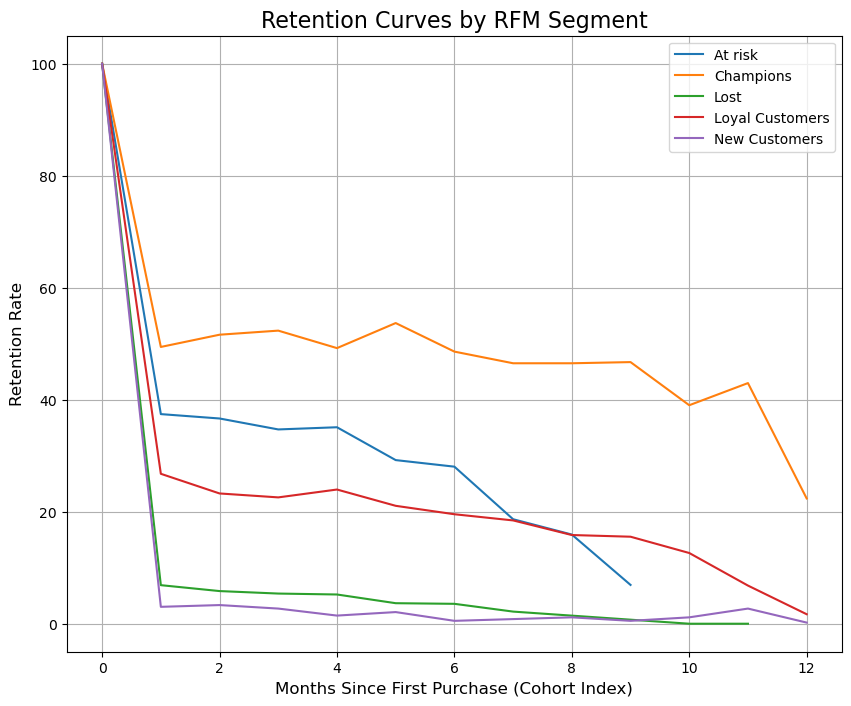

In [96]:
plt.figure(figsize=(10,8))
for row in segment_retention.iterrows():
    plt.plot(row[1].index, row[1].values, label=row[0])
plt.title('Retention Curves by RFM Segment', fontsize=16)
plt.xlabel('Months Since First Purchase (Cohort Index)', fontsize=12)
plt.ylabel('Retention Rate', fontsize=12)
plt.legend()
plt.grid()

Entry Product means the first product a customer bought from the store

Here we are trying to find out which entry products are more likely to convert a customer into a Champion or loyal customer

In [88]:
# Finding the entry product for each customer

When a customer buys multiple items in their first transaction, we must decide which item gets the credit for acquiring them. 
We can use the Hero Product Method here, which assumes that the most expensive item in the cart is the primary driver for the purchase while the cheap ones are just secondary addons.

In [89]:
# Finding the first InvoiceNo for each customer
first_invoice_no = df.sort_values(['CustomerID','InvoiceDate']).groupby('CustomerID')['InvoiceNo'].first().reset_index()
first_invoice_no.head()

,CustomerID,InvoiceNo
0,12346,541431
1,12347,537626
2,12348,539318
3,12349,577609
4,12350,543037


In [112]:
# Filtering the original data to keep only rows containing first invoice no.
#Then sorting on customerid asc and unit price descending so that highest price products come at top
# Again grouping on customerid and choosing the first row from each group to select the most expensive product (Hero product)
primary_entry_product = df[df['InvoiceNo'].isin(first_invoice_no['InvoiceNo'])].sort_values(['CustomerID','UnitPrice'], ascending=[True, False])[['CustomerID','StockCode','ProductName']] #.groupby('CustomerID').first().reset_index()
primary_entry_product.rename(columns={'StockCode': 'EntryProductID', 'ProductName':'EntryProductName'}, inplace=True)

In [113]:
# Joining primary_entry_product with rfm to get customer segments
combined = primary_entry_product.merge(rfm[['CustomerID', 'Customer_Segment']], on='CustomerID')
combined.head()

,CustomerID,EntryProductID,EntryProductName,Customer_Segment
0,12346,23166,Medium ceramic top storage jar,Lost
1,12347,21064,Boom box speaker boys,Champions
2,12347,20782,Camouflage ear muff headphones,Champions
3,12347,85232D,Set/3 decoupage stacking tins,Champions
4,12347,20780,Black ear muff headphones,Champions


In [114]:
# Group by Entry products to count how many customers fall in each RFM segment
segment_counts = combined.groupby(['EntryProductName','Customer_Segment'])['CustomerID'].count().reset_index()
segment_counts

,EntryProductName,Customer_Segment,CustomerID
0,10 colour spaceboy pen,At risk,10
1,10 colour spaceboy pen,Champions,26
2,10 colour spaceboy pen,Lost,18
3,10 colour spaceboy pen,Loyal Customers,22
4,10 colour spaceboy pen,New Customers,7
...,...,...,...
12562,spaceboy baby gift set,New Customers,2
12563,trellis coat rack,Champions,1
12564,trellis coat rack,Lost,2
12565,trellis coat rack,Loyal Customers,3


In [115]:
# Creating a pivot table so that entry products are the rows and RFM segments are columns
product_segment_pivot = segment_counts.pivot_table(index='EntryProductName', columns='Customer_Segment', values='CustomerID', fill_value=0)
product_segment_pivot['Total_Acquired'] = product_segment_pivot.sum(axis=1)
product_segment_pivot

Customer_Segment,At risk,Champions,Lost,Loyal Customers,New Customers,Total_Acquired
EntryProductName,,,,,,
10 colour spaceboy pen,10.0,26.0,18.0,22.0,7.0,83.0
12 coloured party balloons,3.0,6.0,10.0,8.0,1.0,28.0
12 daisy pegs in wood box,1.0,16.0,7.0,6.0,0.0,30.0
12 egg house painted wood,2.0,2.0,7.0,7.0,1.0,19.0
12 hanging eggs hand painted,0.0,0.0,0.0,1.0,2.0,3.0
...,...,...,...,...,...,...
oval wall mirror diamante,1.0,3.0,8.0,5.0,1.0,18.0
red spot gift bag large,0.0,1.0,10.0,6.0,1.0,18.0
set 2 tea towels i love london,11.0,41.0,32.0,28.0,5.0,117.0


In [125]:
# Filtering the products with more than 30 customers
filtered_products = product_segment_pivot[product_segment_pivot['Total_Acquired']>=50]
champion_makers = (filtered_products.div(filtered_products['Total_Acquired'], axis=0)*100).round(1).sort_values(by=['Champions','Loyal Customers'], ascending=False).drop(columns='Total_Acquired')

<Axes: ylabel='EntryProductName'>

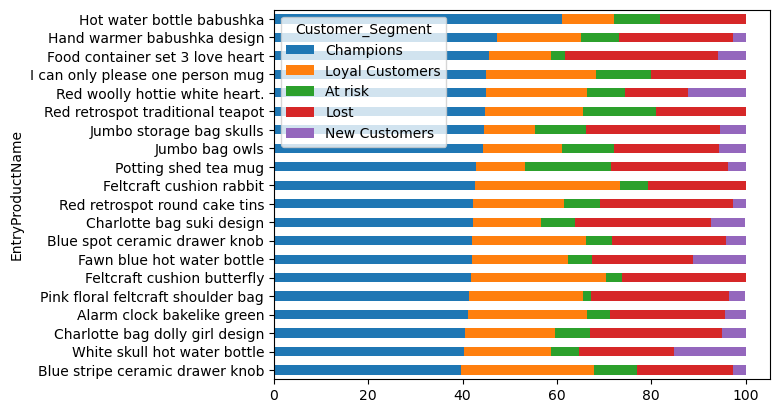

In [126]:
champion_makers = champion_makers[['Champions','Loyal Customers', 'At risk', 'Lost', 'New Customers']].head(20).sort_values('Champions')
champion_makers.plot(kind='barh', stacked=True)